In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

In [2]:
DATA_PATH = "BlinkIT Grocery Data.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            "Place 'BlinkIT Grocery Data.csv' in the same folder as this notebook."
        )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Sales,Rating,Cluster
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,145.4786,5.0,0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,115.3492,5.0,1
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,165.0210,5.0,0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,126.5046,5.0,0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,55.1614,5.0,1


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\\nMissing values:")
display(df.isnull().sum())

print("\\nDuplicate rows:", df.duplicated().sum())

Column names:
['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Sales', 'Rating', 'Cluster']
\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility            8523 non-null   float64
 9   Sales                      8523 non-null

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item Fat Content,8523,5,Low Fat,5089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Identifier,8523,1559,FDW13,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Type,8523,16,Fruits and Vegetables,1232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Establishment Year,8523.0,NaN,NaN,NaN,2016.450546,3.189396,2011.0,2014.0,2016.0,2018.0,2022.0
Outlet Identifier,8523,10,OUT027,935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Location Type,8523,3,Tier 3,3350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Size,8523,3,Medium,3631,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Type,8523,4,Supermarket Type1,5577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Visibility,8523.0,NaN,NaN,NaN,0.066132,0.051598,0.0,0.026989,0.053931,0.094585,0.328391
Sales,8523.0,NaN,NaN,NaN,140.992783,62.275067,31.29,93.8265,143.0128,185.6437,266.8884


\nMissing values:


Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Sales                        0
Rating                       0
Cluster                      0
dtype: int64

\nDuplicate rows: 0


In [4]:
df_clean = df.copy()

# Standardise inconsistent labels in Item Fat Content
if "Item Fat Content" in df_clean.columns:
    df_clean["Item Fat Content"] = (
        df_clean["Item Fat Content"].astype(str).str.strip().str.lower()
        .replace({
            "lf": "low fat",
            "low fat": "low fat",
            "reg": "regular"
        })
        .replace({"low fat": "Low Fat", "regular": "Regular"})
    )

# Remove duplicate records
df_clean = df_clean.drop_duplicates().copy()

# Convert relevant numeric columns to numeric values
numeric_columns = ["Outlet Establishment Year", "Item Visibility", "Sales", "Rating"]
for column in numeric_columns:
    if column in df_clean.columns:
        df_clean[column] = pd.to_numeric(df_clean[column], errors="coerce")

print("Shape after cleaning:", df_clean.shape)
print("\\nMissing values after cleaning:")
display(df_clean.isnull().sum())

Shape after cleaning: (8523, 12)
\nMissing values after cleaning:


Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Sales                        0
Rating                       0
Cluster                      0
dtype: int64

In [5]:
historical_sales = (
    df_clean.dropna(subset=["Outlet Establishment Year", "Sales"])
    .groupby("Outlet Establishment Year")
    .agg(
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Record_Count=("Sales", "count")
    )
    .reset_index()
    .sort_values("Outlet Establishment Year")
)

display(historical_sales.round(2))

,Outlet Establishment Year,Total_Sales,Average_Sales,Record_Count
0,2011,78131.57,140.78,555
1,2012,130476.86,140.30,930
2,2014,131809.02,141.43,932
3,2015,130942.78,140.95,929
4,2016,132113.37,142.06,930
5,2017,133103.91,143.12,930
6,2018,204522.26,139.80,1463
7,2020,129103.96,139.42,926
8,2022,131477.78,141.68,928


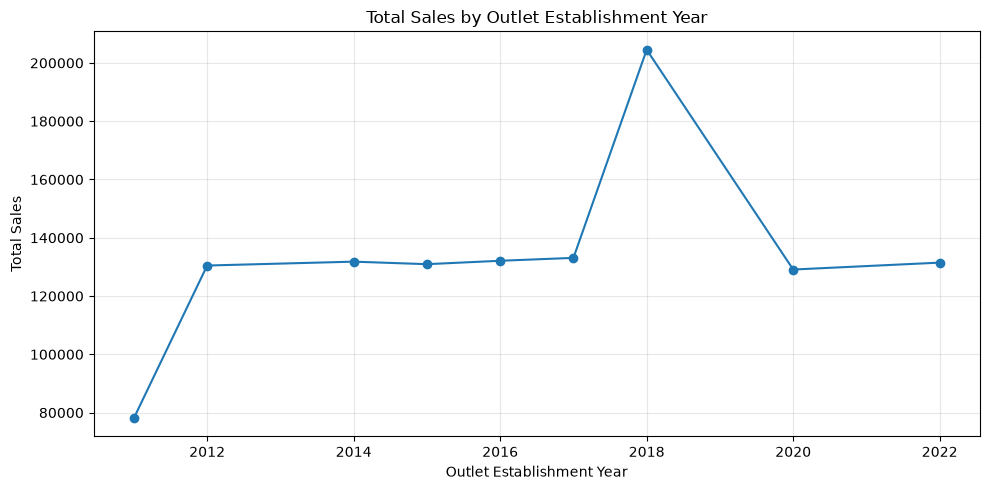

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(
    historical_sales["Outlet Establishment Year"],
    historical_sales["Total_Sales"],
    marker="o"
)
plt.title("Total Sales by Outlet Establishment Year")
plt.xlabel("Outlet Establishment Year")
plt.ylabel("Total Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

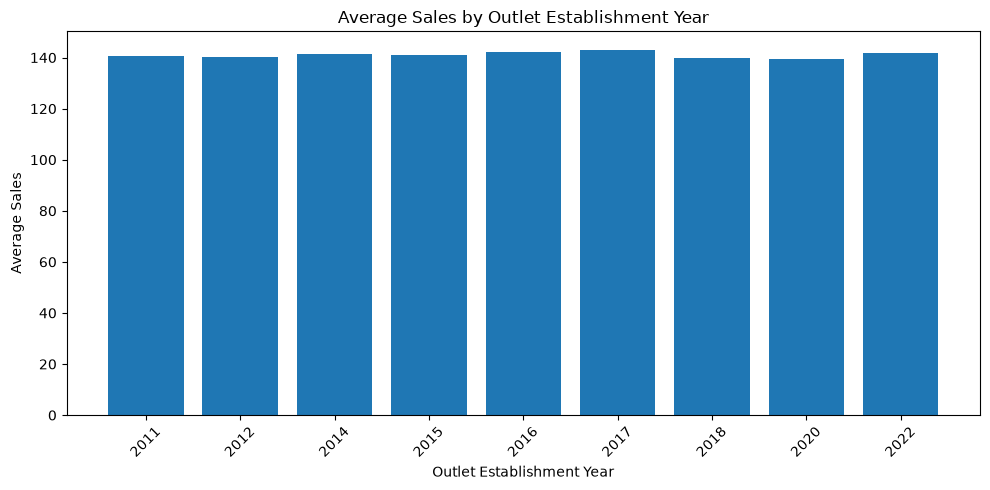

In [7]:
plt.figure(figsize=(10, 5))
plt.bar(
    historical_sales["Outlet Establishment Year"].astype(str),
    historical_sales["Average_Sales"]
)
plt.title("Average Sales by Outlet Establishment Year")
plt.xlabel("Outlet Establishment Year")
plt.ylabel("Average Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
target = "Sales"

categorical_features = [
    "Item Fat Content",
    "Item Type",
    "Outlet Location Type",
    "Outlet Size",
    "Outlet Type"
]

numerical_features = [
    "Outlet Establishment Year",
    "Item Visibility",
    "Rating"
]

required_columns = categorical_features + numerical_features + [target]
model_data = df_clean[required_columns].copy()

# Sales is the target, so rows without a known target value cannot be used
model_data = model_data.dropna(subset=[target])

X = model_data[categorical_features + numerical_features]
y = model_data[target]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Input feature shape: (8523, 8)
Target shape: (8523,)
Categorical features: ['Item Fat Content', 'Item Type', 'Outlet Location Type', 'Outlet Size', 'Outlet Type']
Numerical features: ['Outlet Establishment Year', 'Item Visibility', 'Rating']


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 6818
Testing records: 1705


In [11]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

regression_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

regression_model.fit(X_train, y_train)
print("Random Forest Regression model trained successfully!")

Random Forest Regression model trained successfully!


In [13]:
y_pred = regression_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

display(comparison.head(10).round(2))

,Actual Sales,Predicted Sales
0,183.66,145.13
1,127.34,138.10
2,231.17,197.10
3,188.39,146.10
4,102.63,141.55
5,60.42,104.48
6,56.29,101.20
7,92.54,90.38
8,163.12,157.25
9,165.65,103.92


In [14]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Mean Squared Error (MSE)",
               "Root Mean Squared Error (RMSE)", "R-squared (R2)"],
    "Value": [mae, mse, rmse, r2]
})

display(metrics.round(4))

,Metric,Value
0,Mean Absolute Error (MAE),44.5544
1,Mean Squared Error (MSE),3043.8541
2,Root Mean Squared Error (RMSE),55.1711
3,R-squared (R2),0.2316


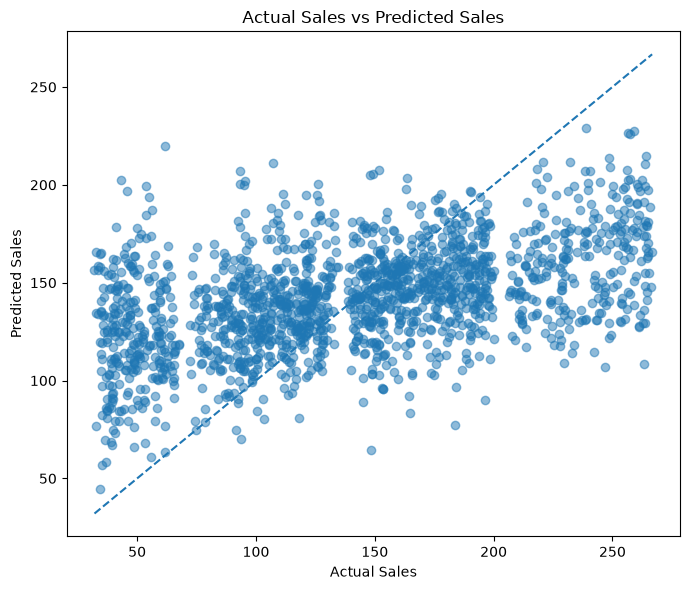

In [15]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], linestyle="--")

plt.title("Actual Sales vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.tight_layout()
plt.show()

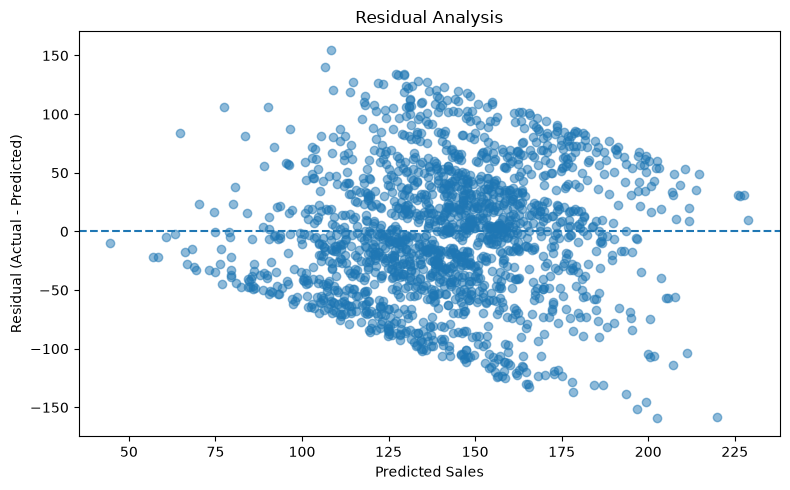

In [16]:
residuals = y_test.values - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.title("Residual Analysis")
plt.xlabel("Predicted Sales")
plt.ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

,Feature,Importance
1,num__Item Visibility,0.514026
2,num__Rating,0.104451
0,num__Outlet Establishment Year,0.053484
11,cat__Item Type_Fruits and Vegetables,0.023373
4,cat__Item Fat Content_Regular,0.021992
18,cat__Item Type_Snack Foods,0.021908
3,cat__Item Fat Content_Low Fat,0.021446
10,cat__Item Type_Frozen Foods,0.020897
9,cat__Item Type_Dairy,0.020532
14,cat__Item Type_Household,0.020169


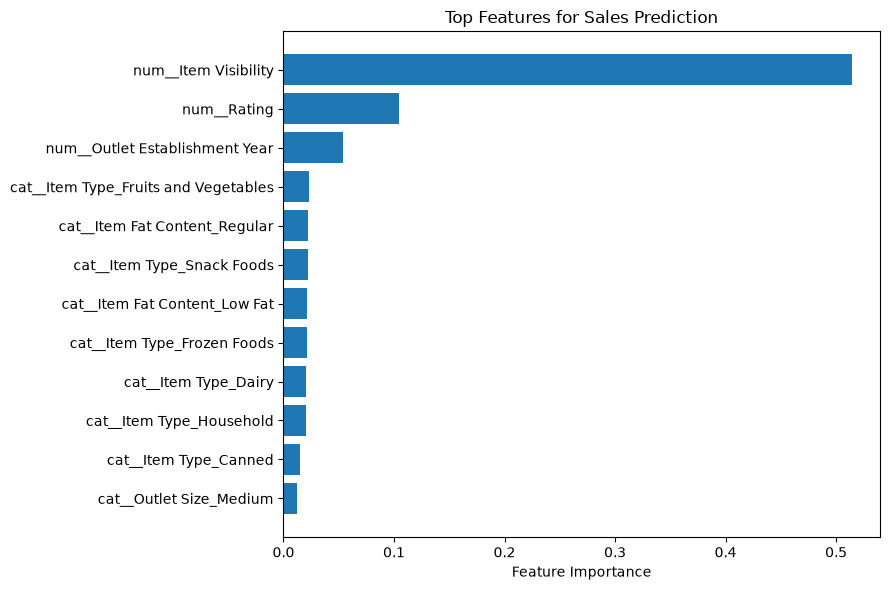

In [17]:
feature_names = regression_model.named_steps["preprocessor"].get_feature_names_out()
importances = regression_model.named_steps["regressor"].feature_importances_

feature_importance = (
    pd.DataFrame({"Feature": feature_names, "Importance": importances})
    .sort_values("Importance", ascending=False)
    .head(12)
)

display(feature_importance)

plt.figure(figsize=(9, 6))
plt.barh(feature_importance["Feature"][::-1], feature_importance["Importance"][::-1])
plt.title("Top Features for Sales Prediction")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()